# Regression with Python

**Student:** Lyn Al Dahr  
**Course:** AAI614 - Data Science & its Applications  
**Week 1:** Git and GitHub exercise

This is a short Google Colab notebook demonstrating linear regression. I used a small **example dataset** of study hours and exam scores so it works without downloading any files.

## 1. Import libraries

I will use pandas for the data, scikit-learn for the model, and Matplotlib to plot the result.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Libraries imported successfully")

Libraries imported successfully


## 2. Create an example dataset

The values below are made up for practice. `hours_studied` is the input feature and `exam_score` is the target.

In [2]:
data = pd.DataFrame({
    "hours_studied": [1, 2, 2, 3, 3, 4, 4, 5, 5, 6, 6, 7, 7, 8, 8, 9, 9, 10, 10, 11, 11, 12, 12, 13],
    "exam_score": [37, 43, 41, 48, 47, 54, 52, 57, 59, 64, 61, 68, 70, 73, 75, 78, 79, 85, 83, 89, 90, 92, 94, 97]
})

print(data.head())
print("Number of rows:", len(data))

   hours_studied  exam_score
0              1          37
1              2          43
2              2          41
3              3          48
4              3          47
Number of rows: 24


## 3. Split the data and train the model

I used 80% of the rows for training and 20% for testing.

In [3]:
X = data[["hours_studied"]]
y = data["exam_score"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

print(f"Intercept: {model.intercept_:.2f}")
print(f"Slope: {model.coef_[0]:.2f}")

Intercept: 32.24
Slope: 5.13


## 4. Check predictions and model performance

In [4]:
predictions = model.predict(X_test)

results = pd.DataFrame({
    "Hours studied": X_test["hours_studied"].values,
    "Actual score": y_test.values,
    "Predicted score": predictions.round(2)
})
print(results.sort_values("Hours studied").to_string(index=False))
print(f"\nMAE: {mean_absolute_error(y_test, predictions):.2f}")
print(f"MSE: {mean_squared_error(y_test, predictions):.2f}")
print(f"R-squared: {r2_score(y_test, predictions):.3f}")

 Hours studied  Actual score  Predicted score
             1            37            37.37
             5            59            57.88
             7            68            68.14
             9            79            78.39
            10            83            83.52

MAE: 0.55
MSE: 0.41
R-squared: 0.998


## 5. Plot the regression line

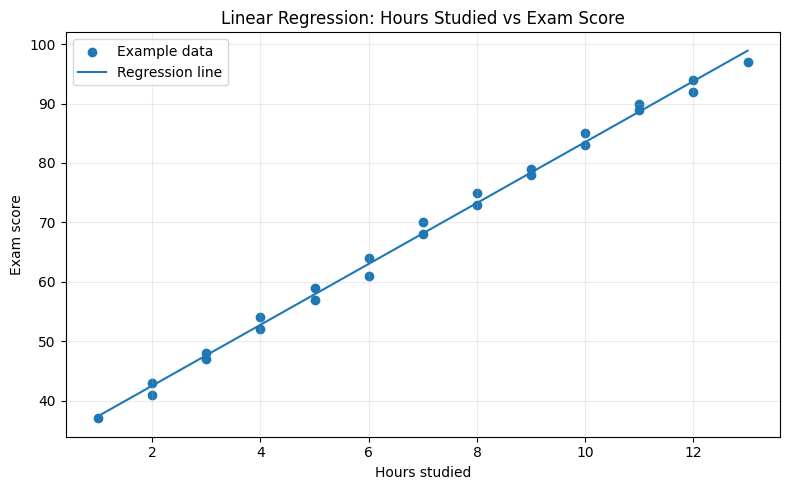

In [5]:
plt.figure(figsize=(8, 5))
plt.scatter(data["hours_studied"], data["exam_score"], label="Example data")
plt.plot(X.sort_values("hours_studied"), model.predict(X.sort_values("hours_studied")), label="Regression line")
plt.xlabel("Hours studied")
plt.ylabel("Exam score")
plt.title("Linear Regression: Hours Studied vs Exam Score")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 6. Conclusion

In this example, exam scores generally increased when the number of study hours increased. Linear regression can estimate the relationship between one numerical input and one numerical output. Since this is a small made-up dataset, the result is just for learning and should not be treated as a real prediction of student performance.